Student Name: Ramya R
Roll Number: 24BAD096
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

PART A: DATASET INFORMATION
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


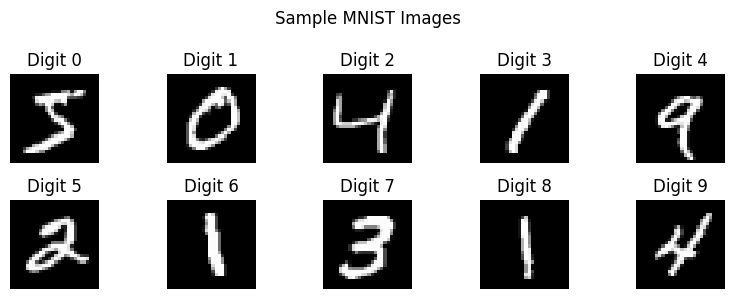

Training data after flattening: (60000, 784)
Testing data after flattening: (10000, 784)
Minimum pixel value: 0.0
Maximum pixel value: 1.0

ENCODER MODEL SUMMARY


Model: "Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_hidden (Dense)          │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_representation (Dense)   │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,608 (408.62 KB)

 Trainable params: 104,608 (408.62 KB)

 Non-trainable params: 0 (0.00 B)

... (9 outputs left out)

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)


PART C: TRAINING THE AUTOENCODER
Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.2287 - val_loss: 0.1497
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.1334 - val_loss: 0.1207
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.1157 - val_loss: 0.1089
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.1073 - val_loss: 0.1029
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.1025 - val_loss: 0.0996
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0996 - val_loss: 0.0972
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0974 - val_loss: 0.0949
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0954 - val_loss: 0.0935
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0938 - val_loss: 0.0920
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.0924 - val_loss: 0.0917

Test reconstruction loss: 0.0917


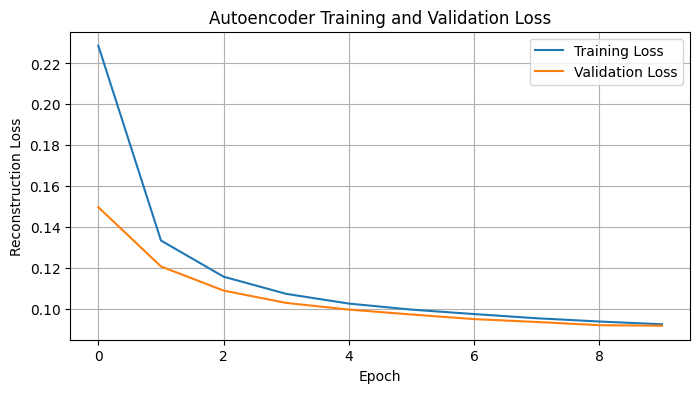


PART D: DIMENSIONALITY REDUCTION
Original dimension: 784
Latent dimension: 32
Latent feature shape: (10, 32)
Reconstructed shape: (10, 784)


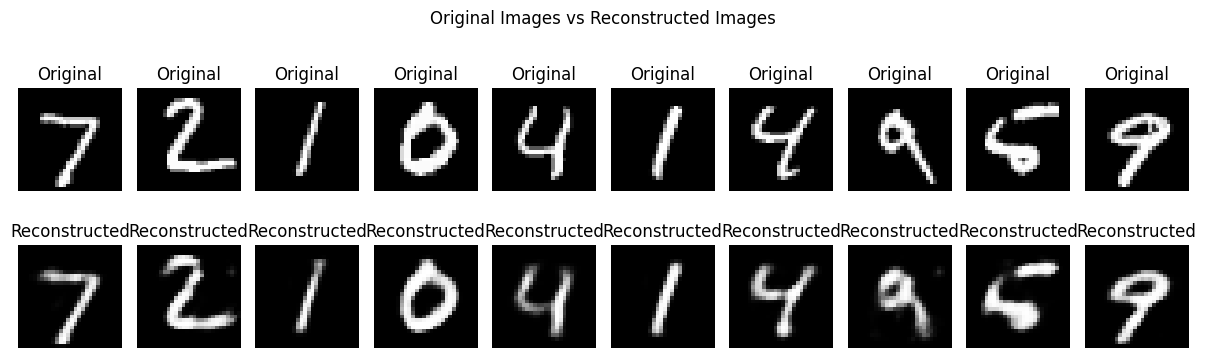

In [1]:

# EXPERIMENT NO: 8
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

print("Student Name: Ramya R")
print("Roll Number: 24BAD096")
# --------------------------------------------------
# PART A: DATASET PREPARATION AND PREPROCESSING
# --------------------------------------------------
# Load the MNIST handwritten digit dataset
(x_train, _), (x_test, _) = mnist.load_data()
print("\nPART A: DATASET INFORMATION")
print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)
# Display sample images
plt.figure(figsize=(8, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Digit {i}")
    plt.axis("off")
plt.suptitle("Sample MNIST Images")
plt.tight_layout()
plt.show()

# Normalize pixel values to the range [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten each 28 x 28 image into 784 features
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("Training data after flattening:", x_train.shape)
print("Testing data after flattening:", x_test.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

# --------------------------------------------------
# PART B: IMPLEMENTING ENCODER AND DECODER
# --------------------------------------------------
input_layer = Input(shape=(784,), name="input_layer")
# Encoder: reduce 784 features to 32 features
encoded = Dense(128, activation="relu",name="encoder_hidden")(input_layer)
latent = Dense(32, activation="relu",name="latent_representation")(encoded)
# Decoder: reconstruct 784 features
decoded = Dense(128, activation="relu",name="decoder_hidden")(latent)
output_layer = Dense(784, activation="sigmoid",name="reconstructed_output")(decoded)
# Create the autoencoder
autoencoder = Model(input_layer, output_layer,name="Autoencoder")
# Create the encoder separately
encoder = Model(input_layer, latent, name="Encoder")
# Create the decoder separately
latent_input = Input(shape=(32,), name="latent_input")
decoder_hidden = autoencoder.get_layer("decoder_hidden")(latent_input)
decoder_output = autoencoder.get_layer("reconstructed_output")(
    decoder_hidden
)
decoder = Model(latent_input, decoder_output, name="Decoder")
print("\nENCODER MODEL SUMMARY")
encoder.summary()
print("\nDECODER MODEL SUMMARY")
decoder.summary()
print("\nAUTOENCODER MODEL SUMMARY")
autoencoder.summary()

# --------------------------------------------------
# PART C: COMPILING AND TRAINING THE AUTOENCODER
# --------------------------------------------------
autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)
print("\nPART C: TRAINING THE AUTOENCODER")
history = autoencoder.fit(
    x_train, x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test),
    verbose=1
)
# Evaluate reconstruction loss on test data
test_loss = autoencoder.evaluate(
    x_test, x_test, verbose=0
)
print("\nTest reconstruction loss:", round(test_loss, 4))
# Plot training and validation loss
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Reconstruction Loss")
plt.title("Autoencoder Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# --------------------------------------------------
# PART D: DIMENSIONALITY REDUCTION AND RECONSTRUCTION
# --------------------------------------------------
# Convert test images into latent feature vectors
latent_features = encoder.predict(x_test[:10], verbose=0)
# Reconstruct images using the decoder
reconstructed_images = decoder.predict(
    latent_features, verbose=0
)

print("\nPART D: DIMENSIONALITY REDUCTION")
print("Original dimension:", x_test.shape[1])
print("Latent dimension:", latent_features.shape[1])
print("Latent feature shape:", latent_features.shape)
print("Reconstructed shape:", reconstructed_images.shape)

# Display original and reconstructed images
plt.figure(figsize=(12, 4))

for i in range(10):
    # Original image
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Reconstructed image
    plt.subplot(2, 10, i + 11)
    plt.imshow(
        reconstructed_images[i].reshape(28, 28),
        cmap="gray"
    )
    plt.title("Reconstructed")
    plt.axis("off")

plt.suptitle("Original Images vs Reconstructed Images")
plt.tight_layout()
plt.show()

# Save the trained model
autoencoder.save("autoencoder_mnist.keras")

